# BrickFinder - YOLO model

First try at finding LEGO pieces in a pile. We fine-tune a pretrained YOLO11s model on the B200 renders
to find 10 kinds of pieces (no data augmentation yet), then test it.

Before running this, download the images and build the dataset from the repo folder:
```
bash scripts/download_data.sh
python scripts/prepare_yolo_dataset.py
```

In [1]:
import json
import os

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display
from ultralytics import YOLO, settings

settings.update({"sync": False})  # turn off ultralytics usage stats

## Settings

In [2]:
DATA = "data/yolo/dataset.yaml"
RUNS = os.path.abspath("runs")  # YOLO needs the full path or it saves the run somewhere else
RUN_NAME = "initial_yolo11s"
IMG_SIZE = 1024  # the images are 2048x2048 so this is half size
DEVICE = "mps"  # mac gpu. use "cpu" or 0 (nvidia gpu) on other computers

# same order as in prepare_yolo_dataset.py
PIECES = ["3001", "3003", "3004", "3005", "3020", "3022", "3023", "3039", "3069b", "3062b"]

## Train

No data augmentation for this first run. YOLO does mosaic, color changes, flips, scaling and shifting by
default, so those are all set to 0. (The dataset readme says not to flip the images anyway, since some
pieces have mirror image versions.)

Takes about 3 minutes per epoch on an M2 Max. The best model gets saved to `runs/initial_yolo11s/weights/best.pt`.

In [3]:
model = YOLO("yolo11s.pt")  # pretrained on COCO

model.train(
    data=DATA,
    imgsz=IMG_SIZE,
    epochs=50,
    patience=10,  # stop early if the val score doesn't improve for 10 epochs
    batch=8,
    cache="ram",  # keep the images in memory so each epoch is faster
    device=DEVICE,
    project=RUNS,
    name=RUN_NAME,
    exist_ok=True,
    # no augmentation
    mosaic=0,
    fliplr=0,
    scale=0,
    translate=0,
    hsv_h=0,
    hsv_s=0,
    hsv_v=0,
)

Ultralytics 8.4.215 🚀 Python-3.12.9 torch-2.15.0 MPS (Apple M2 Max)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=data/yolo/dataset.yaml, degrees=0.0, deterministic=True, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0, hsv_s=0, hsv_v=0, imgsz=1024, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=0, multi_scale=0.0, name=initial_yolo11s, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overlap_mask=Tr

/Users/JoshH./brickfinder/BrickFinder/.venv/lib/python3.12/site-packages/torch/autograd/graph.py:1113: UserWarning: scatter_reduce_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /Users/runner/work/pytorch/pytorch/aten/src/ATen/Context.cpp:224.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass
/Users/JoshH./brickfinder/BrickFinder/.venv/lib/python3.12/site-packages/torch/autograd/graph.py:1113: UserWarning: index_put_with_accumulate_mps does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered 

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x130682270>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.0470

## Training curves

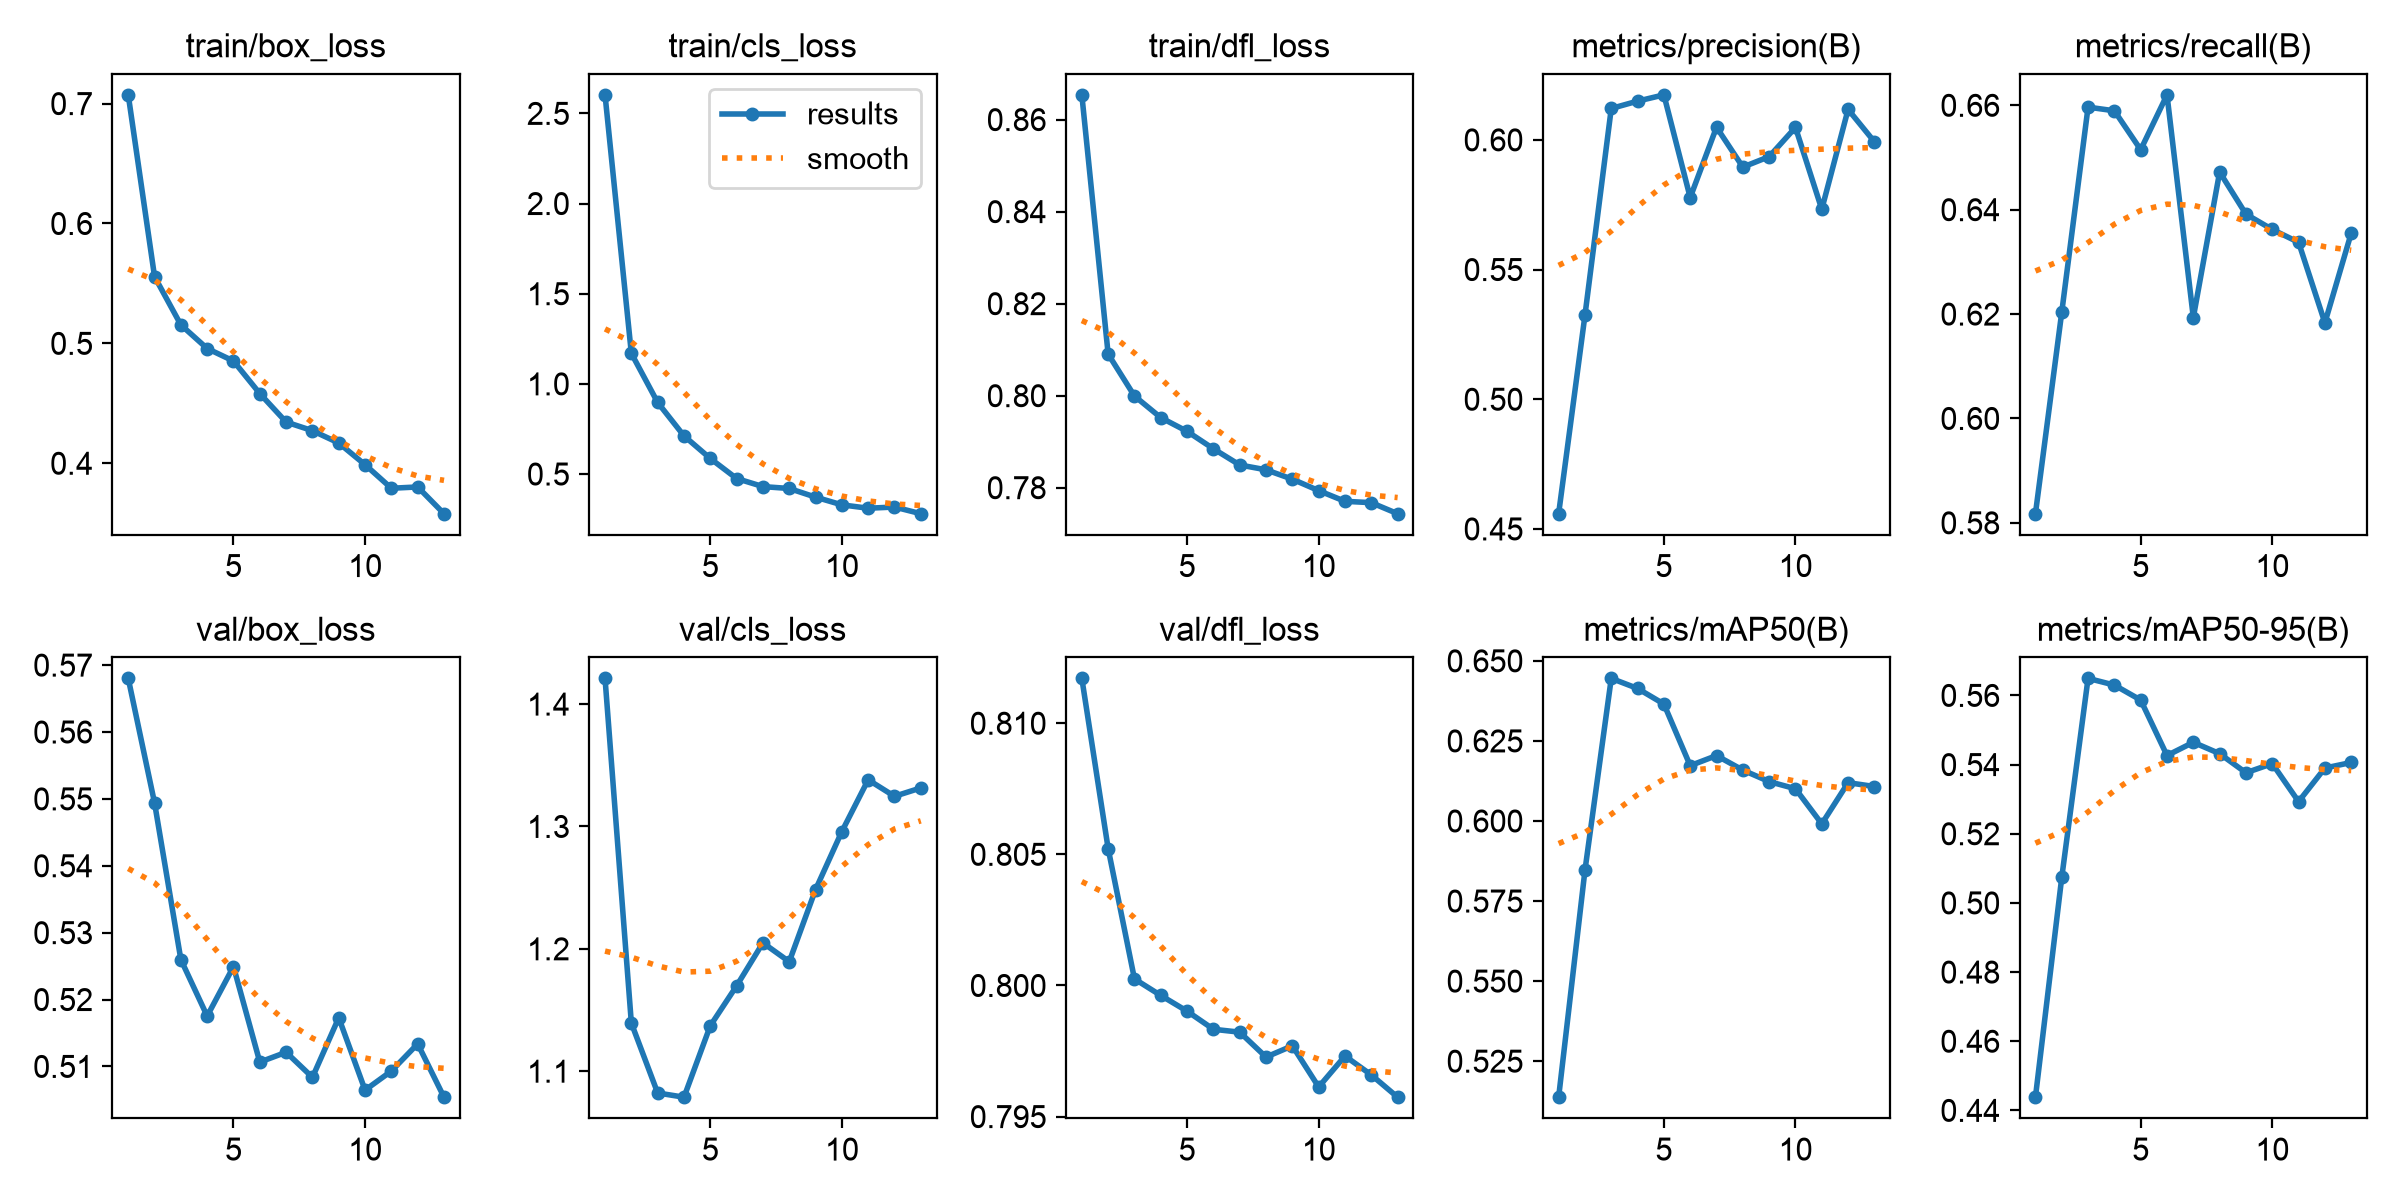

In [4]:
display(Image(f"{RUNS}/{RUN_NAME}/results.png", width=900))

## Test

YOLO's built in test gives precision, recall and mAP for each piece on the 200 test images. These are
computer renders like the training images, not our own photos yet.

In [5]:
model = YOLO(f"{RUNS}/{RUN_NAME}/weights/best.pt")

metrics = model.val(
    data=DATA,
    split="test",
    imgsz=IMG_SIZE,
    batch=8,
    device=DEVICE,
    project=RUNS,
    name=RUN_NAME + "_test",
    exist_ok=True,
)
print("mAP50:", round(metrics.box.map50, 3))
print("mAP50-95:", round(metrics.box.map, 3))

Ultralytics 8.4.215 🚀 Python-3.12.9 torch-2.15.0 MPS (Apple M2 Max)
YOLO11s summary (fused): 100 layers, 9,416,670 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4052.3±339.9 MB/s, size: 7473.2 KB)
val: Scanning /Users/JoshH./brickfinder/BrickFinder/data/yolo/labels/test.cache... 200 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 200/200 209.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 25/25 1.2it/s 20.3s
                   all        200       4000      0.593      0.677      0.641      0.564
        3001_brick_2x4        200        400      0.896      0.915      0.951      0.895
        3003_brick_2x2        200        400      0.921      0.699      0.857      0.768
        3004_brick_1x2        200        400      0.269        0.6      0.267       0.23
        3005_brick_1x1        200        400      0.382      0.445       0.37      0.295
        3020_plate_2x4    

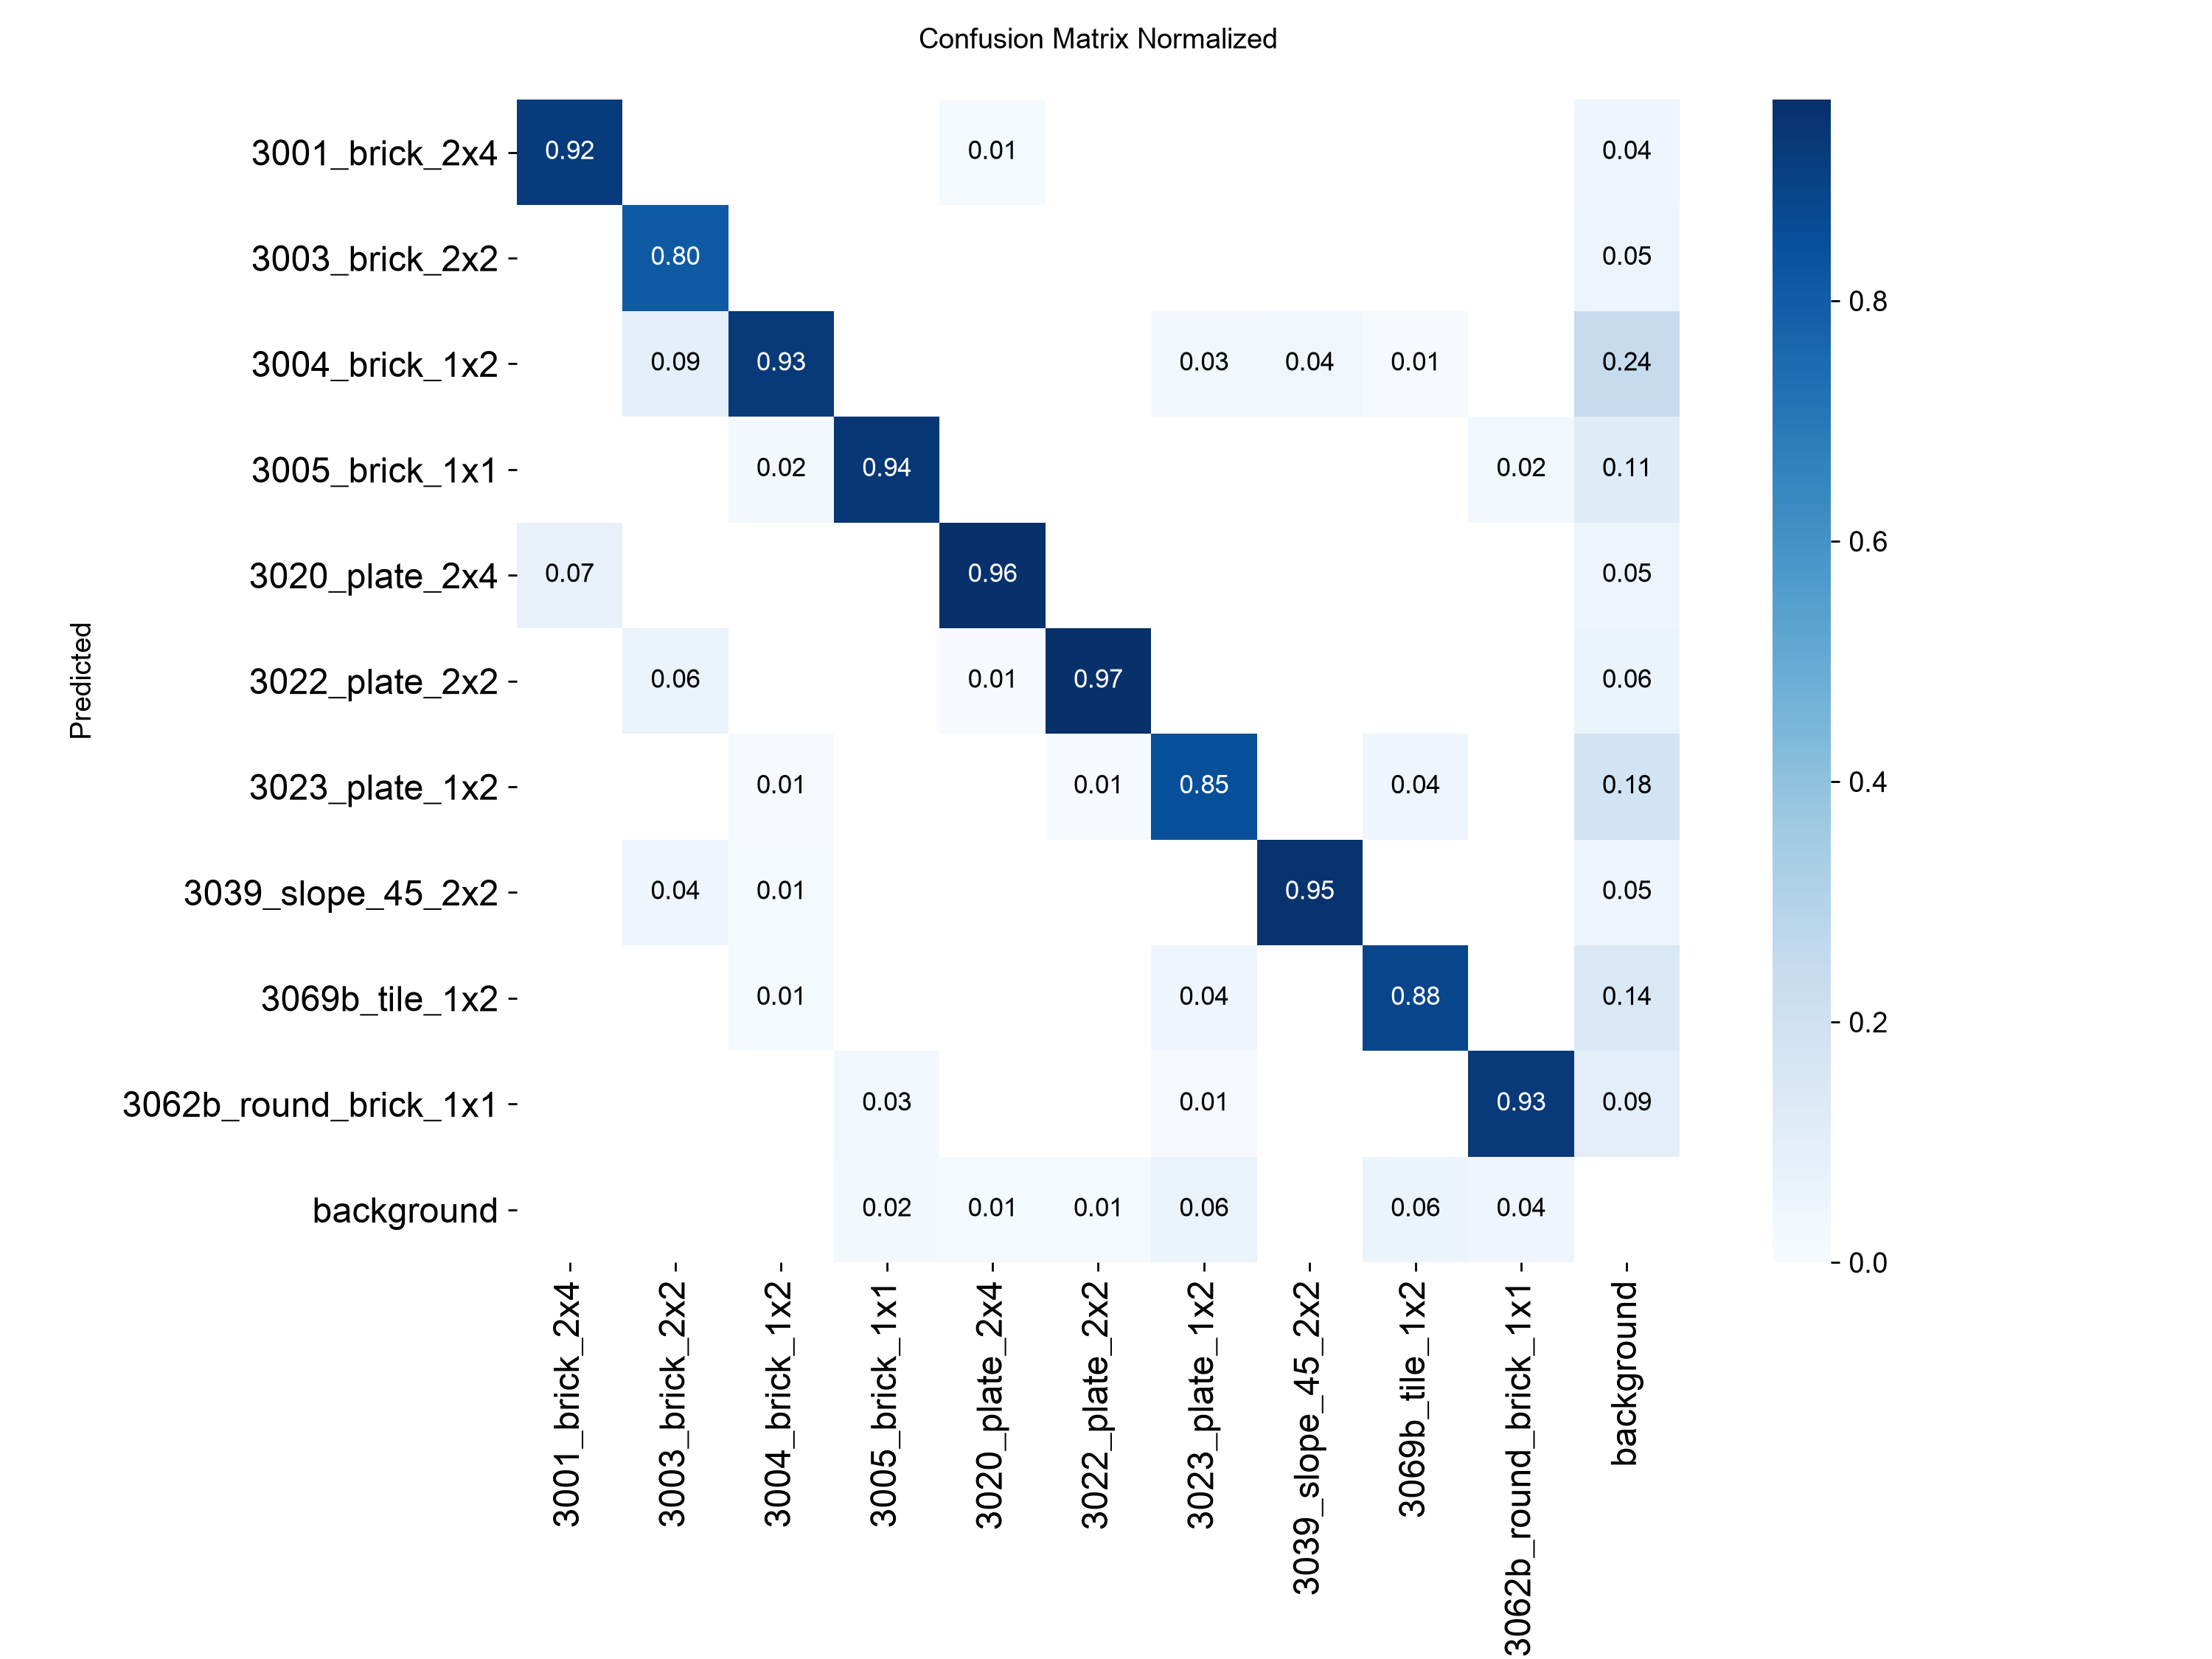

In [6]:
display(Image(f"{RUNS}/{RUN_NAME}_test/confusion_matrix_normalized.png", width=700))

### Metrics from our proposal

- **Precision / recall:** only counts boxes the model is at least 25% sure about. A box is correct if it's
  the right piece and overlaps a real one with IoU >= 0.5.
- **Mean IoU:** how well the correct boxes line up with the real ones.
- **Top-3:** for each test image and piece, is one of the model's 3 best guesses for that piece correct?

In [7]:
def iou(a, b):
    # boxes are [x1, y1, x2, y2]
    w = min(a[2], b[2]) - max(a[0], b[0])
    h = min(a[3], b[3]) - max(a[1], b[1])
    if w <= 0 or h <= 0:
        return 0
    overlap = w * h
    area_a = (a[2] - a[0]) * (a[3] - a[1])
    area_b = (b[2] - b[0]) * (b[3] - b[1])
    return overlap / (area_a + area_b - overlap)

In [8]:
df = pd.read_parquet("data/processed/lego_annotations.parquet")
df = df[df["part_id"].isin(PIECES)]
with open("data/splits.json") as f:
    test_images = json.load(f)["test"]

CONF = 0.25
stats = {p: {"tp": 0, "fp": 0, "real": 0, "ious": [], "top3": 0, "queries": 0} for p in PIECES}

for name in test_images:
    # conf=0.001 keeps the low confidence guesses too so we can rank them for top-3
    result = model.predict(f"data/yolo/images/test/{name}", imgsz=IMG_SIZE, conf=0.001, device=DEVICE, verbose=False)[0]
    boxes = result.boxes.xyxy.tolist()
    confs = result.boxes.conf.tolist()
    classes = result.boxes.cls.tolist()

    for c, piece in enumerate(PIECES):
        s = stats[piece]
        real = df[(df["image_filename"] == name) & (df["part_id"] == piece)]
        real = real[["xmin", "ymin", "xmax", "ymax"]].values.tolist()
        s["real"] += len(real)

        # the model's guesses for this piece, most confident first
        guesses = [(conf, box) for box, conf, cls in zip(boxes, confs, classes) if int(cls) == c]
        guesses.sort(key=lambda g: g[0], reverse=True)

        # match each confident guess to the real box it overlaps most (each real box can only be used once)
        used = []
        for conf, box in guesses:
            if conf < CONF:
                break
            best_iou, best_j = 0, -1
            for j, r in enumerate(real):
                if j not in used and iou(box, r) > best_iou:
                    best_iou, best_j = iou(box, r), j
            if best_iou >= 0.5:
                used.append(best_j)
                s["tp"] += 1
                s["ious"].append(best_iou)
            else:
                s["fp"] += 1

        # top-3
        if len(real) > 0:
            s["queries"] += 1
            if any(iou(box, r) >= 0.5 for conf, box in guesses[:3] for r in real):
                s["top3"] += 1

In [9]:
rows = []
for c, piece in enumerate(PIECES):
    s = stats[piece]
    rows.append({
        "piece": model.names[c],
        "precision": s["tp"] / max(s["tp"] + s["fp"], 1),
        "recall": s["tp"] / s["real"],
        "mean IoU": sum(s["ious"]) / max(len(s["ious"]), 1),
        "top-3": s["top3"] / s["queries"],
        "mAP50": metrics.box.ap50[c],
        "mAP50-95": metrics.box.ap[c],
    })

# totals over all 10 pieces
tp = sum(s["tp"] for s in stats.values())
fp = sum(s["fp"] for s in stats.values())
real = sum(s["real"] for s in stats.values())
ious = [x for s in stats.values() for x in s["ious"]]
top3 = sum(s["top3"] for s in stats.values())
queries = sum(s["queries"] for s in stats.values())
rows.append({
    "piece": "all",
    "precision": tp / max(tp + fp, 1),
    "recall": tp / real,
    "mean IoU": sum(ious) / max(len(ious), 1),
    "top-3": top3 / queries,
    "mAP50": metrics.box.map50,
    "mAP50-95": metrics.box.map,
})

table = pd.DataFrame(rows).round(3)
os.makedirs("results", exist_ok=True)
table.to_csv("results/initial_metrics.csv", index=False)
table

,piece,precision,recall,mean IoU,top-3,mAP50,mAP50-95
0,3001_brick_2x4,0.892,0.910,0.954,1.000,0.951,0.895
1,3003_brick_2x2,0.898,0.725,0.942,0.985,0.857,0.768
2,3004_brick_1x2,0.249,0.672,0.928,0.755,0.267,0.230
3,3005_brick_1x1,0.354,0.608,0.907,0.810,0.370,0.295
4,3020_plate_2x4,0.665,0.930,0.954,0.995,0.867,0.818
5,3022_plate_2x2,0.421,0.798,0.941,0.955,0.665,0.594
6,3023_plate_1x2,0.429,0.428,0.921,0.785,0.398,0.335
7,3039_slope_45_2x2,0.764,0.860,0.929,0.995,0.879,0.763
8,3069b_tile_1x2,0.328,0.668,0.918,0.870,0.439,0.369
9,3062b_round_brick_1x1,0.610,0.678,0.902,0.975,0.716,0.576


## Find a piece

Give it an image and a piece number and it draws boxes around where it thinks that piece is.

found 3 3001_brick_2x4


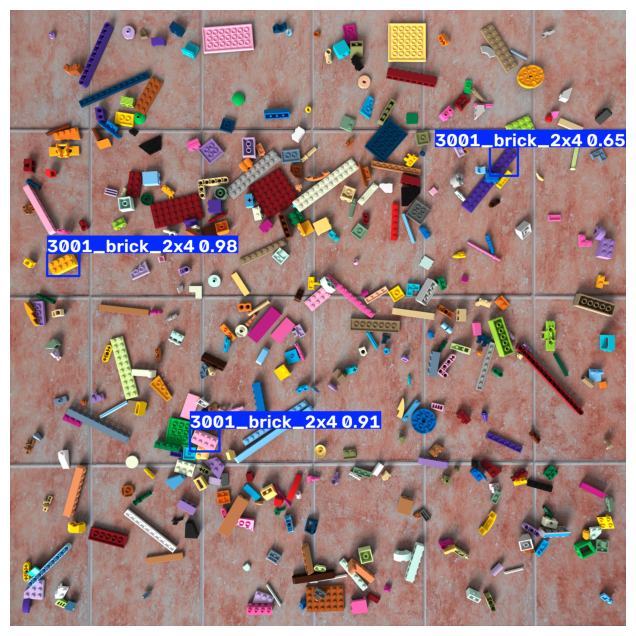

In [10]:
def find_piece(image_path, piece, conf=0.25):
    c = PIECES.index(piece)
    result = model.predict(image_path, imgsz=IMG_SIZE, conf=conf, classes=[c], device=DEVICE, verbose=False)[0]
    print(f"found {len(result.boxes)} {model.names[c]}")
    plt.figure(figsize=(8, 8))
    plt.imshow(result.plot()[:, :, ::-1])  # plot() gives BGR, matplotlib wants RGB
    plt.axis("off")
    plt.show()


find_piece(f"data/yolo/images/test/{test_images[0]}", "3001")